Setup

In [1]:
%load_ext autoreload
%autoreload 2
import pandas as pd
import matplotlib.pyplot as plt
from elexon import fetch_mid, fetch_wind, fetch_demand

START, END = "2026-08-01T00:00Z", "2026-10-01T00:00Z"

Calls

In [2]:
REFRESH = False

if REFRESH:
    fetch_mid(START, END).to_csv("data/mid.csv")
    fetch_wind(START, END).to_csv("data/wind.csv")
    fetch_demand(START, END).to_csv("data/demand.csv")

mid = pd.read_csv("data/mid.csv", index_col="startTime", parse_dates=True)
wind = pd.read_csv("data/wind.csv", index_col="startTime", parse_dates=True)
demand = pd.read_csv("data/demand.csv", index_col="startTime", parse_dates=True)

## Clean and align: inner join on UTC start time

In [3]:
df = pd.concat([mid, wind, demand], axis = 1, join = "inner", sort = True)
local = df.index.tz_convert("Europe/London")
df["hour"] = local.hour
df["weekday"] = local.day_of_week      # 0 = Monday
df["is_weekend"] = df["weekday"] >= 5
assert df.notna().all().all(), "NaNs after merge"
df["residual_mw"] = df["demand_mw"] - df["wind_mw"]
df["wind_gw"] = df["wind_mw"] / 1000
df["demand_gw"] = df["demand_mw"] / 1000
df["residual_gw"] = df["residual_mw"] / 1000
df.to_csv("data/merged.csv")

## Plots

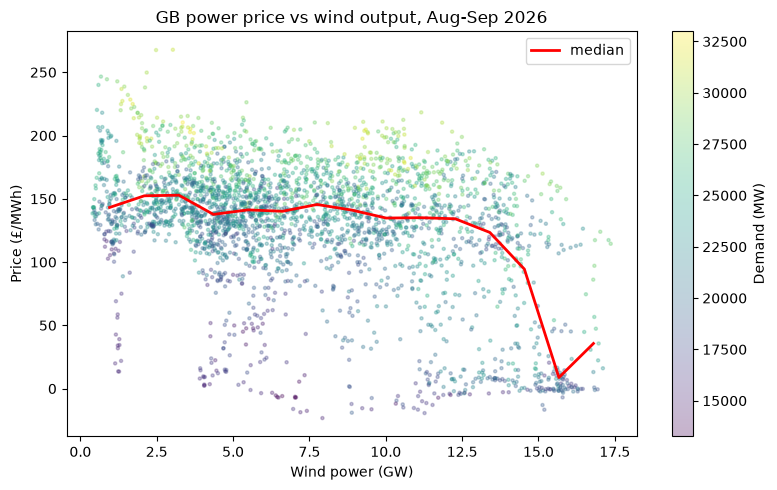

In [4]:
fig, ax = plt.subplots(figsize = (8,5))

sc = ax.scatter(df["wind_mw"] / 1000, df["price"], c=df["demand_mw"], s=5, alpha=0.3, cmap="viridis")
fig.colorbar(sc, ax=ax, label="Demand (MW)")
bins = pd.cut(df["wind_mw"]/1000, bins=15)
med = df.groupby(bins, observed=True)["price"].median()
centres = [interval.mid for interval in med.index]
ax.plot(centres, med.values, color="red", lw=2, label="median")
ax.legend()
ax.set_xlabel("Wind power (GW)")
ax.set_ylabel("Price (£/MWh)")
ax.set_title("GB power price vs wind output, Aug-Sep 2026")
fig.tight_layout()
fig.savefig("figures/price-v-wind.png", dpi=150, bbox_inches="tight")
plt.show()

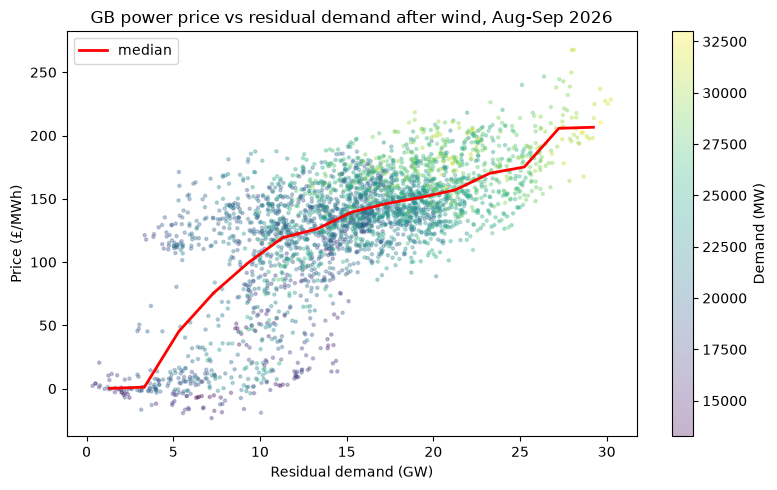

In [5]:
fig, ax = plt.subplots(figsize = (8,5))

sc = ax.scatter(df["residual_mw"] / 1000, df["price"], c=df["demand_mw"], s=5, alpha=0.3, cmap="viridis")
fig.colorbar(sc, ax=ax, label="Demand (MW)")
bins = pd.cut(df["residual_mw"]/1000, bins=15)
med = df.groupby(bins, observed=True)["price"].median()
centres = [interval.mid for interval in med.index]
ax.plot(centres, med.values, color="red", lw=2, label="median")
ax.legend()
ax.set_xlabel("Residual demand (GW)")
ax.set_ylabel("Price (£/MWh)")
ax.set_title("GB power price vs residual demand after wind, Aug-Sep 2026")
fig.tight_layout()
fig.savefig("figures/price-v-residual.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
df[["price", "wind_mw", "residual_mw"]].corr(method="spearman")

,price,wind_mw,residual_mw
price,1.000000,-0.310458,0.660626
wind_mw,-0.310458,1.000000,-0.729759
residual_mw,0.660626,-0.729759,1.000000


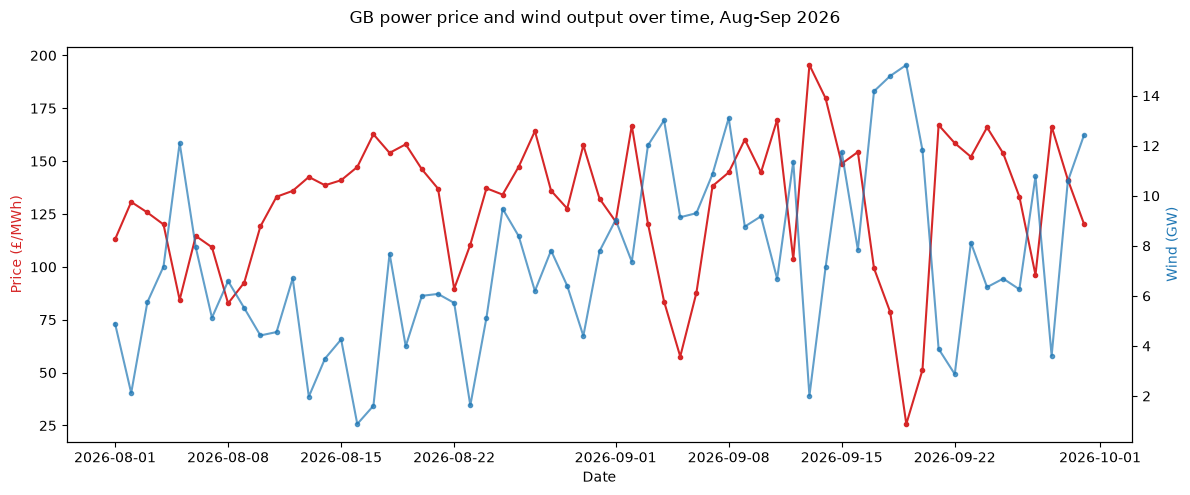

In [7]:
sub = df.tz_convert("Europe/London")[["price", "wind_mw"]].resample("D").mean()
sub = sub.loc[:"2026-09-30"]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(sub.index, sub["price"], lw=1.5, marker="o", ms=3, color="tab:red")
ax.set_ylabel("Price (£/MWh)", color="tab:red")
ax.set_xlabel("Date")

ax2 = ax.twinx()
ax2.plot(sub.index, sub["wind_mw"]/ 1000, lw=1.5, marker="o", ms=3, color="tab:blue", alpha=0.7)
ax2.set_ylabel("Wind (GW)", color="tab:blue")

fig.suptitle("GB power price and wind output over time, Aug-Sep 2026")
fig.tight_layout()
fig.savefig("figures/price-wind-time.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
   import statsmodels.formula.api as smf
   m1 = smf.ols("price ~ wind_gw", data=df).fit(cov_type="HAC", cov_kwds={"maxlags": 48})
   m2 = smf.ols("price ~ wind_gw + demand_gw + C(hour)", data=df).fit(cov_type="HAC", cov_kwds={"maxlags": 48})

In [9]:
m1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.161
Model:                            OLS   Adj. R-squared:                  0.160
Method:                 Least Squares   F-statistic:                     22.20
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           2.57e-06
Time:                        15:55:30   Log-Likelihood:                -15360.
No. Observations:                2925   AIC:                         3.072e+04
Df Residuals:                    2923   BIC:                         3.074e+04
Df Model:                           1                                         
Covariance Type:                  HAC                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    165.7442      7.188     23.057      0.000     151.655     179.833
wind_gw       -4.9065      1.041     -4.712      0.000      -6.948      -2.865
==============================================================================
Omnibus:                      271.533   Durbin-Watson:                   0.062
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              354.886
Skew:                          -0.789   Prob(JB):                     8.66e-78
Kurtosis:                       3.647   Cond. No.                         17.4
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity and autocorrelation robust (HAC) using 48 lags and without small sample correction
"""

In [10]:
m2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.662
Model:                            OLS   Adj. R-squared:                  0.659
Method:                 Least Squares   F-statistic:                     30.14
Date:                Wed, 28 Oct 2026   Prob (F-statistic):          8.52e-126
Time:                        15:55:30   Log-Likelihood:                -14028.
No. Observations:                2925   AIC:                         2.811e+04
Df Residuals:                    2899   BIC:                         2.826e+04
Df Model:                          25                                         
Covariance Type:                  HAC                                         
=================================================================================
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept       -51.5919     18.885     -2.732      0.006     -88.606     -14.577
C(hour)[T.1]      2.7911      1.676      1.666      0.096      -0.493       6.075
C(hour)[T.2]      7.0378      2.092      3.364      0.001       2.937      11.139
C(hour)[T.3]     13.9499      2.678      5.209      0.000       8.701      19.199
C(hour)[T.4]     20.6179      3.161      6.522      0.000      14.422      26.814
C(hour)[T.5]     31.0506      3.260      9.524      0.000      24.661      37.440
C(hour)[T.6]     19.3134      2.955      6.537      0.000      13.522      25.104
C(hour)[T.7]     -7.2405      3.792     -1.910      0.056     -14.672       0.191
C(hour)[T.8]    -25.4419      4.744     -5.363      0.000     -34.740     -16.143
C(hour)[T.9]    -36.1284      5.616     -6.433      0.000     -47.135     -25.122
C(hour)[T.10]   -34.4114      5.751     -5.984      0.000     -45.683     -23.140
C(hour)[T.11]   -36.0272      5.899     -6.107      0.000     -47.589     -24.466
C(hour)[T.12]   -34.3943      6.043     -5.692      0.000     -46.238     -22.550
C(hour)[T.13]   -30.2984      5.964     -5.080      0.000     -41.987     -18.609
C(hour)[T.14]   -28.2385      5.721     -4.936      0.000     -39.452     -17.025
C(hour)[T.15]   -24.5355      5.421     -4.526      0.000     -35.161     -13.910
C(hour)[T.16]   -25.2540      4.532     -5.572      0.000     -34.136     -16.371
C(hour)[T.17]   -16.9503      4.668     -3.631      0.000     -26.100      -7.801
C(hour)[T.18]   -19.2482      6.019     -3.198      0.001     -31.046      -7.450
C(hour)[T.19]   -23.5160      6.222     -3.779      0.000     -35.711     -11.321
C(hour)[T.20]   -25.6873      5.628     -4.564      0.000     -36.718     -14.657
C(hour)[T.21]   -22.6901      4.123     -5.503      0.000     -30.772     -14.609
C(hour)[T.22]   -11.0593      2.599     -4.256      0.000     -16.153      -5.966
C(hour)[T.23]    -1.7327      1.346     -1.287      0.198      -4.371       0.906
wind_gw          -4.9483      0.740     -6.690      0.000      -6.398      -3.499
demand_gw        10.1475      0.883     11.495      0.000       8.417      11.878
==============================================================================
Omnibus:                       21.446   Durbin-Watson:                   0.126
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               21.801
Skew:                          -0.207   Prob(JB):                     1.84e-05
Kurtosis:                       2.910   Cond. No.                         596.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity and autocorrelation robust (HAC) using 48 lags and without small sample correction
"""

In [14]:
m2.t_test("wind_gw + demand_gw = 0")

<class 'statsmodels.stats.contrast.ContrastResults'>
                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0             5.1993      0.988      5.264      0.000       3.263       7.135

In [11]:
   import statsmodels.formula.api as smf
   m1_nolag = smf.ols("price ~ wind_gw", data=df).fit()
   m2_nolag = smf.ols("price ~ wind_gw + demand_gw + C(hour)", data=df).fit()

In [12]:
m1_nolag.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.161
Model:                            OLS   Adj. R-squared:                  0.160
Method:                 Least Squares   F-statistic:                     559.6
Date:                Wed, 28 Oct 2026   Prob (F-statistic):          2.38e-113
Time:                        15:55:31   Log-Likelihood:                -15360.
No. Observations:                2925   AIC:                         3.072e+04
Df Residuals:                    2923   BIC:                         3.074e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    165.7442      1.746     94.932      0.000     162.321     169.168
wind_gw       -4.9065      0.207    -23.657      0.000      -5.313      -4.500
==============================================================================
Omnibus:                      271.533   Durbin-Watson:                   0.062
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              354.886
Skew:                          -0.789   Prob(JB):                     8.66e-78
Kurtosis:                       3.647   Cond. No.                         17.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [13]:
m2_nolag.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.662
Model:                            OLS   Adj. R-squared:                  0.659
Method:                 Least Squares   F-statistic:                     227.5
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:55:31   Log-Likelihood:                -14028.
No. Observations:                2925   AIC:                         2.811e+04
Df Residuals:                    2899   BIC:                         2.826e+04
Df Model:                          25                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept       -51.5919      5.676     -9.090      0.000     -62.720     -40.463
C(hour)[T.1]      2.7911      3.784      0.738      0.461      -4.628      10.210
C(hour)[T.2]      7.0378      3.793      1.856      0.064      -0.399      14.475
C(hour)[T.3]     13.9499      3.812      3.659      0.000       6.475      21.425
C(hour)[T.4]     20.6179      3.829      5.385      0.000      13.110      28.126
C(hour)[T.5]     31.0506      3.826      8.116      0.000      23.549      38.552
C(hour)[T.6]     19.3134      3.785      5.102      0.000      11.892      26.735
C(hour)[T.7]     -7.2405      3.800     -1.906      0.057     -14.691       0.210
C(hour)[T.8]    -25.4419      3.819     -6.662      0.000     -32.930     -17.954
C(hour)[T.9]    -36.1284      3.800     -9.508      0.000     -43.579     -28.678
C(hour)[T.10]   -34.4114      3.783     -9.097      0.000     -41.828     -26.994
C(hour)[T.11]   -36.0272      3.783     -9.523      0.000     -43.445     -28.609
C(hour)[T.12]   -34.3943      3.786     -9.085      0.000     -41.817     -26.971
C(hour)[T.13]   -30.2984      3.792     -7.991      0.000     -37.733     -22.864
C(hour)[T.14]   -28.2385      3.793     -7.445      0.000     -35.676     -20.801
C(hour)[T.15]   -24.5355      3.784     -6.485      0.000     -31.954     -17.117
C(hour)[T.16]   -25.2540      3.797     -6.652      0.000     -32.698     -17.810
C(hour)[T.17]   -16.9503      3.898     -4.349      0.000     -24.593      -9.308
C(hour)[T.18]   -19.2482      4.007     -4.804      0.000     -27.104     -11.392
C(hour)[T.19]   -23.5160      4.069     -5.779      0.000     -31.495     -15.537
C(hour)[T.20]   -25.6873      4.032     -6.370      0.000     -33.594     -17.781
C(hour)[T.21]   -22.6901      3.933     -5.769      0.000     -30.402     -14.979
C(hour)[T.22]   -11.0593      3.827     -2.890      0.004     -18.564      -3.555
C(hour)[T.23]    -1.7327      3.792     -0.457      0.648      -9.168       5.703
wind_gw          -4.9483      0.132    -37.423      0.000      -5.208      -4.689
demand_gw        10.1475      0.225     45.097      0.000       9.706      10.589
==============================================================================
Omnibus:                       21.446   Durbin-Watson:                   0.126
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               21.801
Skew:                          -0.207   Prob(JB):                     1.84e-05
Kurtosis:                       2.910   Cond. No.                         596.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [16]:
m3 = smf.ols("price ~ residual_gw + I(residual_gw**2) + C(hour)", data=df).fit(cov_type="HAC", cov_kwds={"maxlags": 48})

In [17]:
m3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.646
Model:                            OLS   Adj. R-squared:                  0.642
Method:                 Least Squares   F-statistic:                     35.86
Date:                Wed, 28 Oct 2026   Prob (F-statistic):          2.54e-149
Time:                        16:00:36   Log-Likelihood:                -14099.
No. Observations:                2925   AIC:                         2.825e+04
Df Residuals:                    2899   BIC:                         2.841e+04
Df Model:                          25                                         
Covariance Type:                  HAC                                         
=======================================================================================
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -0.4548     14.888     -0.031      0.976     -29.635      28.726
C(hour)[T.1]            0.4802      1.551      0.310      0.757      -2.560       3.520
C(hour)[T.2]            2.6230      1.991      1.317      0.188      -1.280       6.526
C(hour)[T.3]            6.8514      2.453      2.793      0.005       2.044      11.659
C(hour)[T.4]           11.9288      2.851      4.184      0.000       6.341      17.516
C(hour)[T.5]           22.0728      3.060      7.214      0.000      16.076      28.070
C(hour)[T.6]           15.7420      3.004      5.240      0.000       9.854      21.630
C(hour)[T.7]           -0.8430      3.632     -0.232      0.816      -7.961       6.275
C(hour)[T.8]          -15.4843      4.106     -3.771      0.000     -23.531      -7.437
C(hour)[T.9]          -29.3738      5.048     -5.818      0.000     -39.268     -19.479
C(hour)[T.10]         -32.9627      5.379     -6.129      0.000     -43.505     -22.421
C(hour)[T.11]         -37.4461      5.619     -6.664      0.000     -48.460     -26.432
C(hour)[T.12]         -36.7370      5.800     -6.334      0.000     -48.105     -25.369
C(hour)[T.13]         -34.1359      5.673     -6.017      0.000     -45.255     -23.017
C(hour)[T.14]         -32.6057      5.438     -5.995      0.000     -43.265     -21.946
C(hour)[T.15]         -26.5110      5.064     -5.235      0.000     -36.436     -16.586
C(hour)[T.16]         -19.3434      4.220     -4.584      0.000     -27.614     -11.073
C(hour)[T.17]           2.1487      3.762      0.571      0.568      -5.225       9.522
C(hour)[T.18]           9.6936      4.489      2.159      0.031       0.894      18.493
C(hour)[T.19]          10.6457      4.418      2.410      0.016       1.987      19.304
C(hour)[T.20]           5.1393      3.936      1.306      0.192      -2.574      12.853
C(hour)[T.21]          -0.3112      3.159     -0.098      0.922      -6.503       5.881
C(hour)[T.22]           0.1990      2.223      0.090      0.929      -4.158       4.556
C(hour)[T.23]           0.8569      1.343      0.638      0.523      -1.775       3.489
residual_gw            12.7808      1.561      8.187      0.000       9.721      15.840
I(residual_gw ** 2)    -0.2209      0.044     -4.982      0.000      -0.308      -0.134
==============================================================================
Omnibus:                        0.154   Durbin-Watson:                   0.103
Prob(Omnibus):                  0.926   Jarque-Bera (JB):                0.142
Skew:                          -0.017   Prob(JB):                        0.932
Kurtosis:                       3.005   Cond. No.                     7.84e+03
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity and au

In [20]:
thr = df["price"].quantile(0.99)
spikes = df[df["price"] >= thr]
cols = ["price", "wind_gw", "demand_gw", "residual_gw", "volume"]

comparison = pd.DataFrame({
    "all periods": df[cols].median(),
    "spikes": spikes[cols].median(),
})
comparison.round(1)

,all periods,spikes
price,139.3,224.9
wind_gw,6.6,1.7
demand_gw,22.3,29.3
residual_gw,15.6,27.5
volume,2703.3,3996.1


In [21]:
print(f"Spike threshold (99th pct): £{thr:.0f}/MWh, n = {len(spikes)}")
print(f"Spikes fall on {spikes.index.normalize().nunique()} distinct days")
pct = (df["residual_gw"] < spikes["residual_gw"].median()).mean()
print(f"Median spike sits at the {pct:.0%} percentile of residual demand")
spikes["hour"].value_counts().sort_index()

Spike threshold (99th pct): £214/MWh, n = 30
Spikes fall on 8 distinct days
Median spike sits at the 99% percentile of residual demand


hour
15     1
16     2
17     7
18    10
19     8
20     2
Name: count, dtype: int64